# LoRaWAN Join-Accept Replay Detection: Dataset Generation and ML Evaluation

## Purpose

This notebook runs a controlled experiment on detecting Join-Accept replay attacks at a
LoRaWAN gateway. It combines two earlier notebooks (dataset generation and ML
evaluation) into one pipeline that follows the experiment workflow step by step.

1. Parse the PCAP.
2. Audit the capture.
   2b. Lengthen the timeline by laying copies of the real capture end to end.
3. Choose the benign source: use the real Join-Accepts, or simulate more if there are too few.
4. Generate the replays, using a naive and a timing-aware attacker.
5. Compute the behavioural features at the gateway.
6. Split the timeline into time blocks, remove the block edges (the purge) and split by block.
7. Train the models: Random Forest, Logistic Regression, Isolation Forest and a baseline.
8. Evaluate: confusion matrix, precision, recall, F1, false positive rate, AUC, recall per
   attacker, training time, inference time and model size.
9. Show the leakage effect.
10. Repeat Steps 3 to 8 with different seeds and report the mean and spread.
11. Run the extra checks reported in Chapters 3 to 5 of the dissertation.

## Labels

- `Label = 0`: benign traffic.
- `Label = 1`: a Join-Accept replay, meaning an injected copy of an earlier Join-Accept.

## What is real and what is simulated

- **Real (from the capture):** every rxpk and txpk entry parsed from the PCAP, including
  its timing, radio settings, message type and payload.
- **Simulated, only where needed:** the capture contains just one real Join-Accept, which is
  too few to build a dataset (Step 3 checks this). So extra benign Join-Request and
  Join-Accept sessions are simulated on top of the real background traffic. They use the
  capture's own timeline and channels, so the simulated joins sit inside real traffic and
  not a fully artificial setting.
- **Looped, to make the dataset bigger:** the capture is only about 15 minutes long, so
  Step 2b lays `N_CAPTURE_LOOPS` time-shifted copies of the real background traffic end
  to end. The looped rows are real packets, but the background pattern repeats every
  loop; the simulated joins and replays on top are fresh in every loop.
- **Always simulated:** the replay attacks. A replay is an attacker re-sending a message
  they recorded earlier. Step 4 builds each replay by picking a victim Join-Accept and a
  seed, an earlier Join-Accept at least 60 s older with a different payload. The seed is
  copied back in after the victim, by one of two attackers (naive or timing-aware, both
  described in Step 4). Most seeds are simulated, because most Join-Accepts are.

## How to run

Set the path to your capture file in the cell below, then run all cells in order.

In [1]:
# ---------------------------------------------------------------------
# Imports and configuration
# ---------------------------------------------------------------------
from __future__ import annotations

import base64
import hashlib
import json
import pickle
import re
import struct
import time as _time

import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# --- path to the capture to analyse ---
PCAP_PATH = "normaltraffic.pcap"

# --- reproducibility ---
SEED = 42
rng = np.random.default_rng(SEED)

# --- design constants (see the markdown cells above each step for why) ---
LOOKBACK_CAP_S = 60.0        # furthest back any time-based feature looks
TRAFFIC_WINDOW_S = 10.0      # "recent traffic volume" window
MIN_SEED_AGE_S = 60.0        # a replay seed must be >=60s older than its victim
BLOCK_MIN_WIDTH_S = 120.0    # blocks must be well above the 60s lookback
MAX_BLOCKS_CAP = 30          # don't go higher than this even for very long captures
TEST_FRACTION = 0.4         # ~40% of blocks held out for test
RX1_DELAY_S = 5.0            # LoRaWAN Join-Accept RX1 window
RX2_DELAY_S = 6.0            # LoRaWAN Join-Accept RX2 window
MIN_CAPTURED_JOINACCEPTS = 15    # "enough Join-Accepts" threshold (Step 3)
COLLISION_THRESHOLD = 0.01   # guard band so synthetic timestamps don't collide with ones
BACKOFF_STEP = 0.015
# --- dataset size (see Step 2b and Step 10) ---
N_CAPTURE_LOOPS = 10          # copies of the real background capture laid end to end (1 = original capture only)
REPLAY_SESSION_FRACTION = 0.18  # share of eligible victims that are attacked (gives 15 sessions with 1 loop)
N_MULTI_SEED_RUNS = 10       # repeats of Steps 3-8 with different seeds (Step 10)

MTYPE_NAMES = {
    0: "JoinRequest", 1: "JoinAccept", 2: "UnconfirmedDataUp",
    3: "UnconfirmedDataDown", 4: "ConfirmedDataUp", 5: "ConfirmedDataDown",
    6: "RFU", 7: "Proprietary",
}

FEATURES = [
    "time_since_prev_joinaccept",
    "time_since_last_joinrequest",
    "joinaccepts_after_that_request",
    "window_error_s",
    "channel_consistency",
    "freq_change",
    "recent_traffic_volume",
]


## Step 1: Parse the PCAP

This step reads a Semtech UDP packet-forwarder capture and pulls out every rxpk entry
(an uplink) and every txpk entry (a downlink). For each entry it records:

- **Direction:** uplink or downlink.
- **Message type:** read from the top 3 bits of the first payload byte (the LoRaWAN MHDR),
  which shows whether it is a Join-Request, a Join-Accept or a data message.
- **Radio fields:** frequency, spreading factor and bandwidth, coding rate, RSSI, SNR
  and transmit power.
- **Payload:** its size, the raw payload and a hash of it (used later to spot repeated
  payloads).
- **Timing:** the capture time from the PCAP frame, and the `tmst` value as reported
  inside the JSON.

The parser uses only Python's standard library. It reads the Ethernet, IPv4 and UDP
headers directly with `struct`, so it does not need `scapy` and runs in environments
where `scapy` is not installed. If the file is not a classic PCAP (for example a pcapng
file), it falls back to `scapy` automatically, when `scapy` is available.

In [2]:
# ---------------------------------------------------------------------
# Step 1 -- PCAP parsing
# ---------------------------------------------------------------------

def _extract_forwarder_json(udp_payload: bytes):
    """Extract the JSON body from a Semtech UDP packet-forwarder message.

    Header: version(1) token(2) identifier(1). PUSH_DATA (0x00) then has an
    8-byte gateway EUI before the JSON; PULL_RESP (0x03) has the JSON straight
    after the header. Do NOT search for b"{": the random token can contain 0x7B.
    """
    if len(udp_payload) < 5:
        return None
    ident = udp_payload[3]
    if ident == 0x00:      # PUSH_DATA (rxpk / stat)
        start = 12
    elif ident == 0x03:    # PULL_RESP (txpk)
        start = 4
    else:                  # ACKs, PULL_DATA, TX_ACK etc: not radio entries
        return None
    try:
        return json.loads(udp_payload[start:].decode("utf-8"))
    except (ValueError, UnicodeDecodeError):
        return None


def _normalise_entries(obj):
    '''Return a list of (entry_dict, direction) pairs from a Semtech JSON object.'''
    entries = []
    for key, direction in (("rxpk", "uplink"), ("txpk", "downlink")):
        val = obj.get(key)
        if val is None:
            continue
        if isinstance(val, list):
            entries.extend((e, direction) for e in val)
        elif isinstance(val, dict):
            entries.append((val, direction))
    return entries


def _parse_udp_packets_from_pcap(path: str):
    '''
    Dependency-free classic-pcap (libpcap) reader. Walks Ethernet II ->
    (optional 802.1Q VLAN) -> IPv4 -> UDP and yields (capture_time, udp_payload).
    Falls back to scapy for non-classic-pcap files (e.g. pcapng), if installed.
    '''
    results = []
    with open(path, "rb") as fh:
        global_header = fh.read(24)
        if len(global_header) < 24:
            return results
        magic = global_header[:4]
        if magic == b"\xa1\xb2\xc3\xd4":
            endian, usec = ">", True
        elif magic == b"\xd4\xc3\xb2\xa1":
            endian, usec = "<", True
        elif magic == b"\xa1\xb2\x3c\x4d":
            endian, usec = ">", False
        elif magic == b"\x4d\x3c\xb2\xa1":
            endian, usec = "<", False
        else:
            try:
                from scapy.all import PcapReader, UDP
                with PcapReader(path) as pcap:
                    for pkt in pcap:
                        if pkt.haslayer(UDP):
                            results.append((float(pkt.time), bytes(pkt[UDP].payload)))
            except Exception:
                pass
            return results

        while True:
            rec_header = fh.read(16)
            if len(rec_header) < 16:
                break
            ts_sec, ts_frac, incl_len, _orig_len = struct.unpack(endian + "IIII", rec_header)
            frame = fh.read(incl_len)
            if len(frame) < incl_len:
                break
            capture_time = ts_sec + ts_frac / (1_000_000 if usec else 1_000_000_000)
            try:
                offset = 0
                if len(frame) < offset + 14:
                    continue
                eth_type = struct.unpack(">H", frame[offset + 12:offset + 14])[0]
                offset += 14
                if eth_type == 0x8100:  # 802.1Q VLAN tag
                    if len(frame) < offset + 4:
                        continue
                    eth_type = struct.unpack(">H", frame[offset + 2:offset + 4])[0]
                    offset += 4
                if eth_type != 0x0800:  # IPv4
                    continue
                if len(frame) < offset + 20:
                    continue
                ihl = (frame[offset] & 0x0F) * 4
                proto = frame[offset + 9]
                if proto != 17:  # UDP
                    continue
                ip_total_len = struct.unpack(">H", frame[offset + 2:offset + 4])[0]
                udp_start = offset + ihl
                if len(frame) < udp_start + 8:
                    continue
                udp_payload = frame[udp_start + 8: offset + ip_total_len] or frame[udp_start + 8:]
                results.append((capture_time, udp_payload))
            except (struct.error, IndexError):
                continue
    return results


def parse_pcap_to_dataframe(path: str) -> pd.DataFrame:
    '''
    Parse every rxpk/txpk in a Semtech UDP-forwarder PCAP into one row per
    radio entry, with direction, message type (from the MHDR), radio fields,
    size, payload, capture time and tmst.
    '''
    rows = []
    for capture_time, udp_payload in _parse_udp_packets_from_pcap(path):
        obj = _extract_forwarder_json(udp_payload)
        if not obj:
            continue
        for entry, direction in _normalise_entries(obj):
            if not isinstance(entry, dict):
                continue
            data_b64 = entry.get("data")
            if not data_b64:
                continue
            try:
                raw = base64.b64decode(data_b64)
            except Exception:
                continue
            if not raw:
                continue

            mtype = (raw[0] >> 5) & 0x07  # LoRaWAN MHDR: top 3 bits = MType
            datr = entry.get("datr", "SF12BW125")
            sf_match = re.match(r"SF(\d+)BW(\d+)", datr)
            sf, bw = (int(sf_match.group(1)), int(sf_match.group(2))) if sf_match else (12, 125)

            rows.append({
                "capture_time": capture_time,
                "tmst": entry.get("tmst"),
                "direction": direction,
                "message_type": MTYPE_NAMES.get(mtype, f"Unknown({mtype})"),
                "frequency_mhz": float(entry.get("freq", 868.1)),
                "spreading_factor": sf,
                "bandwidth_khz": bw,
                "coding_rate": entry.get("codr", "4/5"),
                "rssi": float(entry["rssi"]) if "rssi" in entry else np.nan,
                "snr": float(entry["lsnr"]) if "lsnr" in entry else np.nan,
                "tx_power_dbm": float(entry["powe"]) if "powe" in entry else np.nan,
                "packet_size": len(raw),
                "payload_b64": data_b64,
                "payload_hash": hashlib.sha1(raw).hexdigest(),
            })

    cols = ["capture_time", "tmst", "direction", "message_type", "frequency_mhz",
            "spreading_factor", "bandwidth_khz", "coding_rate", "rssi", "snr",
            "tx_power_dbm", "packet_size", "payload_b64", "payload_hash"]
    if not rows:
        return pd.DataFrame(columns=cols)
    return pd.DataFrame(rows).sort_values("capture_time").reset_index(drop=True)


_df = parse_pcap_to_dataframe(PCAP_PATH)
_df["Label"] = 0
_df["scenario"] = "benign"
_df["session_id"] = -1
_df["victim_time"] = np.nan
_df["seed_time"] = np.nan
_df["source"] = "_capture"

print(f"Parsed {len(_df)} radio entries from {PCAP_PATH}")
display(_df.head())


Parsed 260 radio entries from normaltraffic.pcap


,capture_time,tmst,direction,message_type,frequency_mhz,spreading_factor,bandwidth_khz,coding_rate,rssi,snr,tx_power_dbm,packet_size,payload_b64,payload_hash,Label,scenario,session_id,victim_time,seed_time,source
0,1.684572e+09,1684572126,uplink,JoinRequest,868.1,7,125,4/5,-60.0,7.0,NaN,23,AAAAAAAAAAAAc1EcE4p7cYMJaN91AgA=,106b900faa28060aedc96e8593814ace3ce69186,0,benign,-1,NaN,NaN,_capture
1,1.684572e+09,1689572126,downlink,JoinAccept,868.1,7,125,4/5,NaN,NaN,14.0,33,IJ86NFgormd8QstP7kDGFC5TRmQaZdMola6Xc96bYuKS,0bc2f698c805545f49dc72b969d7f215b8cd4d41,0,benign,-1,NaN,NaN,_capture
2,1.684572e+09,1684572138,uplink,ConfirmedDataUp,867.9,12,125,4/5,-60.0,7.0,NaN,17,gKWH1gAAAAAB73IGWLbtjC0=,5bdc0c6e40b7656aca11da33b6573434237aada4,0,benign,-1,NaN,NaN,_capture
3,1.684572e+09,1685572138,downlink,UnconfirmedDataDown,867.9,12,125,4/5,NaN,NaN,14.0,13,YKWH1gChAAAGIe3N6A==,10012d6c1b9191b5603290b26451324d969798f1,0,benign,-1,NaN,NaN,_capture
4,1.684572e+09,1684572145,uplink,ConfirmedDataUp,867.3,12,125,4/5,-60.0,7.0,NaN,20,gKWH1gADAQAGAD0BOATUgjYRZ0c=,cd79800abc307fa9800bd25877fbc6e63b4128a7,0,benign,-1,NaN,NaN,_capture


## Step 2: Audit the capture

This step builds a table of the packets in the capture, counted by direction and message
type. Each cell also shows how many of those rows have a payload that appears more than
once. The table shows how many real Join-Accepts the capture contains, and that count
decides what happens in Step 3.

In [3]:
# ---------------------------------------------------------------------
# Step 2 -- Audit the capture
# ---------------------------------------------------------------------

def audit_capture(df: pd.DataFrame) -> pd.DataFrame:
    '''Tabulate packets by direction and message type, with repeated
    payloads per cell.'''
    if df.empty:
        return pd.DataFrame()

    counts = df.pivot_table(
        index="direction", columns="message_type", values="payload_hash",
        aggfunc="count", fill_value=0,
    )

    dup = (df.groupby(["direction", "message_type", "payload_hash"])
           .size().reset_index(name="n"))
    dup = dup[dup["n"] > 1]
    dup_pivot = dup.pivot_table(
        index="direction", columns="message_type", values="n",
        aggfunc="sum", fill_value=0,
    )
    dup_pivot = dup_pivot.reindex(index=counts.index, columns=counts.columns, fill_value=0)

    return counts.astype(str) + " (" + dup_pivot.astype(int).astype(str) + " dup-rows)"


display(audit_capture(_df))


message_type,ConfirmedDataUp,JoinAccept,JoinRequest,UnconfirmedDataDown
direction,,,,
downlink,0 (0 dup-rows),1 (0 dup-rows),0 (0 dup-rows),129 (0 dup-rows)
uplink,129 (0 dup-rows),0 (0 dup-rows),1 (0 dup-rows),0 (0 dup-rows)


## Step 2b: Lengthen the timeline

The capture is only about 15 minutes long (908 s). That limits everything downstream: only
about 110 Join-Accepts fit on the timeline, the 60 s purge removes roughly 40% of them
because the blocks are only about 130 s wide, and the test set ends up with only 6
replays.

To get a bigger dataset without inventing new background traffic, the real capture is
laid end to end `N_CAPTURE_LOOPS` times. Each loop:

- is a copy of every real rxpk and txpk entry, shifted forward in time by one capture
  length plus one typical packet gap, so the loops join without an artificial silence;
- has its `tmst` counter shifted by the same amount (wrapping at 2^32, as a real
  gateway counter does), so the scheduled-time feature stays consistent;
- gets loop-specific payload hashes, so a looped copy of the real Join-Accept is not
  mistaken for a replay by the baseline. Only the hash is changed; the payload bytes
  stay as captured;
- is tagged `source = "_capture_loop"` and `loop_id = k`, so looped rows can be told
  apart from the original capture (`loop_id = 0`).

Step 3 then simulates fresh, independent Join sessions over the whole lengthened
timeline, and Step 4 attacks a fixed share (`REPLAY_SESSION_FRACTION`) of the eligible
victims, so the class balance stays the same as in the one-loop run.

**What this does and does not do.** It gives more Join-Accepts, more replays, wider blocks
(so the purge removes a smaller share) and a bigger test set. It does not add new real
traffic: the background pattern repeats every loop. Setting `N_CAPTURE_LOOPS = 1`
gives the single-capture setup.

The loops are only used when the capture has too few real Join-Accepts (Step 3). If a
capture has enough of them, looping would repeat real Join-Accepts, so it is skipped.


In [4]:
# ---------------------------------------------------------------------
# Step 2b -- Lengthen the timeline by looping the real background capture
# ---------------------------------------------------------------------

def extend_background(df: pd.DataFrame, n_loops: int) -> pd.DataFrame:
    """Lay n_loops time-shifted copies of the real capture end to end."""
    base = df.copy()
    base["loop_id"] = 0
    if n_loops <= 1:
        return base
    times = np.sort(base["capture_time"].to_numpy())
    span = times[-1] - times[0]
    gap = float(np.median(np.diff(times))) if len(times) > 1 else 1.0
    period = span + gap                       # one capture length + one typical gap

    copies = [base]
    for k in range(1, n_loops):
        c = base.copy()
        c["capture_time"] = c["capture_time"] + k * period
        c["tmst"] = (c["tmst"].astype(float) + k * period * 1e6) % 2**32
        c["payload_hash"] = c["payload_hash"].map(
            lambda h, k=k: hashlib.sha1(f"{h}-loop{k}".encode()).hexdigest())
        c["source"] = "_capture_loop"
        c["loop_id"] = k
        copies.append(c)
    return pd.concat(copies, ignore_index=True).sort_values("capture_time").reset_index(drop=True)


_preview = extend_background(_df, N_CAPTURE_LOOPS)
print(f"Original capture: {len(_df)} rows over "
      f"{_df['capture_time'].max() - _df['capture_time'].min():.0f}s")
print(f"With {N_CAPTURE_LOOPS} loop(s): {len(_preview)} rows over "
      f"{_preview['capture_time'].max() - _preview['capture_time'].min():.0f}s")
del _preview


Original capture: 260 rows over 908s
With 10 loop(s): 2600 rows over 9088s


## Step 3: Choose the benign source

This step decides where the benign Join-Accepts come from.

**If the capture has enough real Join-Accepts** (at least `MIN_CAPTURED_JOINACCEPTS`
distinct payloads), those are used directly as the benign source. Any rows with an
exactly duplicated payload are reported and dropped first. Duplicates like these are
artefacts of the capture, not attacks, so they are not labelled as replays.

**If there are too few**, which is the usual case for a short capture made up mostly of
ordinary data traffic, benign Join-Request and Join-Accept sessions are simulated. The
simulation:

- uses the same timing as the real capture. In the capture, the network server's txpk
  reaches the gateway about 0.33 s after the request (0.23 to 0.45 s), and its `tmst`
  schedules the transmission for exactly RX1 (5 s after the request's `tmst`) or RX2
  (6 s after). Each simulated Join-Accept is therefore given a latency drawn from the
  capture's real latencies, and a `tmst` exactly 5 s (85%) or 6 s (15%) after its
  request;
- is placed on top of the real background traffic and uses the capture's own channels,
  so it is not a wholly artificial timeline;
- avoids exact, noise-free timing. An earlier version placed every simulated Join-Accept
  exactly 5.000 or 6.000 s after its request, while replays landed at jittered times. A
  model could then separate the classes by how they were generated rather than how they
  behave, which is a form of leakage;
- includes two kinds of benign oddity: an occasional missed request (no Join-Accept
  follows) and occasional bursts of several devices joining together.

In [5]:
# ---------------------------------------------------------------------
# Step 3 -- Choose / build the benign source
# ---------------------------------------------------------------------

def count_captured_joinaccepts(df: pd.DataFrame) -> int:
    ja = df[(df["message_type"] == "JoinAccept") & (df["direction"] == "downlink")]
    return ja["payload_hash"].nunique()


def dedupe_captured_joinaccepts(df: pd.DataFrame) -> tuple[pd.DataFrame, int]:
    '''Drop duplicate-payload Join-Accept rows already present in the
    capture; report how many were removed. Keeps the earliest occurrence.'''
    ja_mask = (df["message_type"] == "JoinAccept") & (df["direction"] == "downlink")
    ja = df[ja_mask].sort_values("capture_time")
    keep_idx = ja.drop_duplicates(subset="payload_hash", keep="first").index
    n_dropped = ja_mask.sum() - len(keep_idx)
    cleaned = df[~ja_mask | df.index.isin(keep_idx)].copy()
    return cleaned, int(n_dropped)


def inject_simulated_joins(_df: pd.DataFrame, rng: np.random.Generator,
                            target_interval_s: float = 12.0):
    '''Simulate benign Join-Request/Join-Accept sessions (RX1/RX2 timing,
    an occasional missed request, occasional simultaneous joins) spread
    across the capture's own timeline and channel set.'''
    start, end = _df["capture_time"].min(), _df["capture_time"].max()
    existing_ts = np.sort(_df["capture_time"].to_numpy())
    channels = sorted(_df["frequency_mhz"].dropna().unique().tolist()) or [868.1]

    def avoid_collision(t: float) -> float:
        while True:
            pos = np.searchsorted(existing_ts, t)
            collide = ((pos > 0 and abs(t - existing_ts[pos - 1]) < COLLISION_THRESHOLD) or
                       (pos < len(existing_ts) and abs(existing_ts[pos] - t) < COLLISION_THRESHOLD))
            if not collide:
                return t
            t += BACKOFF_STEP

    # How long after an uplink the network server's txpk reaches the gateway in the
    # REAL capture. Benign Join-Accepts are given these real latencies, so their arrival
    # times carry the same jitter as real traffic and are not an exact 5.000 / 6.000 s
    # (that exactness would be a fingerprint of the simulator, not of benign behaviour).
    _s = _df.sort_values("capture_time")
    _up_t = _s.loc[_s["direction"] == "uplink", "capture_time"].to_numpy()
    _dn_t = _s.loc[_s["direction"] == "downlink", "capture_time"].to_numpy()
    _pos = np.searchsorted(_up_t, _dn_t) - 1
    _lat = _dn_t[_pos >= 0] - _up_t[_pos[_pos >= 0]]
    latency_pool = _lat[(_lat > 0) & (_lat < 2.0)]
    if len(latency_pool) == 0:
        latency_pool = np.array([0.33])

    rows, counter = [], 0

    def new_hash(tag: str) -> str:
        nonlocal counter
        counter += 1
        return hashlib.sha1(f"{tag}-{counter}-{rng.random()}".encode()).hexdigest()

    t = start + rng.uniform(5, target_interval_s)
    while t < end:
        burst_size = int(rng.integers(2, 4)) if rng.random() < 0.08 else 1
        for _ in range(burst_size):
            freq = float(rng.choice(channels))
            req_time = avoid_collision(t + rng.uniform(0, 0.3))
            req_tmst = int(req_time * 1e6) % (2**32)
            rows.append(dict(
                capture_time=req_time, tmst=req_tmst,
                direction="uplink", message_type="JoinRequest", frequency_mhz=freq,
                spreading_factor=12, bandwidth_khz=125, coding_rate="4/5",
                rssi=-60.0 + rng.normal(0, 2), snr=7.0 + rng.normal(0, 1),
                tx_power_dbm=np.nan, packet_size=23, payload_b64=None,
                payload_hash=new_hash("REQ"), Label=0, scenario="benign",
                session_id=-1, victim_time=np.nan, seed_time=np.nan, source="simulated_join",
            ))
            if rng.random() < 0.05:  # a request that never gets answered
                continue
            delay = RX1_DELAY_S if rng.random() < 0.85 else RX2_DELAY_S
            # As in the real capture: the txpk reaches the gateway shortly after the
            # request (real network-server latency), and is SCHEDULED via tmst for
            # exactly RX1 (5 s) or RX2 (6 s) after the request's tmst.
            acc_time = avoid_collision(req_time + float(rng.choice(latency_pool)))
            rows.append(dict(
                capture_time=acc_time, tmst=(req_tmst + int(delay * 1e6)) % (2**32),
                direction="downlink", message_type="JoinAccept", frequency_mhz=freq,
                spreading_factor=7, bandwidth_khz=125, coding_rate="4/5",
                rssi=np.nan, snr=np.nan, tx_power_dbm=14.0, packet_size=33, payload_b64=None,
                payload_hash=new_hash("ACC"), Label=0, scenario="benign",
                session_id=-1, victim_time=np.nan, seed_time=np.nan, source="simulated_join",
            ))
        t += (target_interval_s * rng.uniform(0.5, 1.5)) if burst_size == 1 else rng.uniform(3.0, 8.0)

    sim_df = pd.DataFrame(rows)
    merged = pd.concat([_df, sim_df], ignore_index=True).sort_values("capture_time").reset_index(drop=True)
    return merged, sim_df


_df, n_dropped = dedupe_captured_joinaccepts(_df)
print(f"Dropped {n_dropped} duplicate-payload Join-Accept rows already present in the capture.")

n_captured_ja = count_captured_joinaccepts(_df)
print(f" distinct Join-Accept payloads: {n_captured_ja} (threshold: {MIN_CAPTURED_JOINACCEPTS})")

if n_captured_ja >= MIN_CAPTURED_JOINACCEPTS:
    print("-> Enough Join-Accepts: using them directly as the benign source.")
    # Enough real Join-Accepts: do not loop the capture, because looping would
    # repeat real Join-Accepts and blur the line between benign and replay.
    benign_stream, sim_joins = _df.copy(), pd.DataFrame()
else:
    print("-> Too few captured Join-Accepts: simulating benign Join-Request/Join-Accept "
          "sessions on top of the captured background traffic.")
    background = extend_background(_df, N_CAPTURE_LOOPS)
    print(f"   Background traffic: {N_CAPTURE_LOOPS} loop(s) of the capture -> {len(background)} rows, "
          f"{background['capture_time'].max() - background['capture_time'].min():.0f}s timeline.")
    benign_stream, sim_joins = inject_simulated_joins(background, rng)
    n_sim_ja = int((sim_joins["message_type"] == "JoinAccept").sum()) if len(sim_joins) else 0
    print(f"   Simulated {n_sim_ja} additional Join-Accept sessions "
          f"({len(benign_stream) - len(sim_joins)} background rows + {len(sim_joins)} simulated rows -> {len(benign_stream)} total).")

display(benign_stream["message_type"].value_counts())


Dropped 0 duplicate-payload Join-Accept rows already present in the capture.
 distinct Join-Accept payloads: 1 (threshold: 15)
-> Too few captured Join-Accepts: simulating benign Join-Request/Join-Accept sessions on top of the captured background traffic.
   Background traffic: 10 loop(s) of the capture -> 2600 rows, 9088s timeline.
   Simulated 826 additional Join-Accept sessions (2600 background rows + 1698 simulated rows -> 4298 total).


message_type
ConfirmedDataUp        1290
UnconfirmedDataDown    1290
JoinRequest             882
JoinAccept              836
Name: count, dtype: int64

## Step 4: Generate the replays

Each attack **session** picks two Join-Accepts:

- a **victim**: a legitimate Join-Accept;
- a **seed**: a different, earlier Join-Accept recorded at least 60 s before the
  victim. The seed stands for the message the attacker recorded earlier. It is never an
  invented payload, because a replay is by definition an earlier message sent again.

A victim with no eligible seed (typically one early in the capture) is skipped. The
seed's own original row stays labelled 0, and only the re-injected copies are labelled 1.

About half of the sessions use the **naive** attacker and half use the **timing-aware**
attacker. A `scenario` column records which, so each can be reported separately. Each
session injects 1 to 3 replay copies.

### Naive attacker

The naive attacker replays a recorded Join-Accept exactly as it was and knows nothing
about the current request. Every field comes from the seed: the payload, its size, the
frequency, the spreading factor, the power and the old scheduled `tmst`. Nothing comes
from the victim.

- The first copy arrives 8 to 180 s after the victim's Join-Accept, and is not tied to
  any request. Further copies follow 0.5 to 1 s apart.
- Because the `tmst` is stale and the radio fields come from a different session, the
  window error should usually be large, and the channel often will not match the most
  recent request.
- This is the easier case, so the expectation is that detection should be easier.

### Timing-aware attacker

The timing-aware attacker knows which receive slot the legitimate Join-Accept used and
tries to land in the same slot. Only the payload and its size come from the seed. The
frequency, spreading factor, power and scheduled `tmst` all come from the victim.

- The window error is therefore close to zero and the channel check passes.
- The first copy arrives 0.05 to 0.8 s after the legitimate Join-Accept. Further copies
  follow 0.5 to 1 s apart.
- The remaining giveaways are behavioural: a second Join-Accept after the same request,
  a very short gap to the previous Join-Accept, and a small burst of nearby traffic.
- This models a strong attacker who knows the scheduled slot, so it is the hard case and
  a worst case for the detector.

In [6]:
# ---------------------------------------------------------------------
# Step 4 -- Generate replays (naive + timing-aware attackers)
# ---------------------------------------------------------------------

def generate_replays(stream: pd.DataFrame, rng: np.random.Generator,
                      n_sessions: int | None = None) -> pd.DataFrame:
    ja = (stream[(stream["message_type"] == "JoinAccept") & (stream["direction"] == "downlink")]
          .sort_values("capture_time").reset_index(drop=True))
    if ja.empty:
        return pd.DataFrame()
    ja_times = ja["capture_time"].to_numpy()

    # A victim is eligible only if some other Join-Accept lies >=60s before it
    # with a different payload.
    eligible_victim_idx = []
    for i in range(len(ja)):
        cutoff = ja_times[i] - MIN_SEED_AGE_S
        cand = ja[(ja["capture_time"] <= cutoff) & (ja["payload_hash"] != ja.iloc[i]["payload_hash"])]
        if not cand.empty:
            eligible_victim_idx.append(i)

    if not eligible_victim_idx:
        print("No eligible victims (no Join-Accept has a seed >=60s earlier). No replays generated.")
        return pd.DataFrame()

    if n_sessions is None:  # scale the attack count with the number of eligible victims
        n_sessions = max(1, int(round(REPLAY_SESSION_FRACTION * len(eligible_victim_idx))))
    n_sessions = min(n_sessions, len(eligible_victim_idx))
    print(f"Eligible victims: {len(eligible_victim_idx)} -> attacking {n_sessions} "
          f"({n_sessions / len(eligible_victim_idx):.0%})")
    chosen = np.sort(rng.choice(eligible_victim_idx, size=n_sessions, replace=False))

    # About half naive, half timing-aware: a balanced, shuffled assignment.
    scenarios = np.array(["naive", "timing_aware"] * ((n_sessions + 1) // 2))[:n_sessions]
    rng.shuffle(scenarios)

    rows, session_id = [], 0
    for k, i in enumerate(chosen):
        victim = ja.iloc[i]
        cutoff = victim["capture_time"] - MIN_SEED_AGE_S
        eligible = ja[(ja["capture_time"] <= cutoff) & (ja["payload_hash"] != victim["payload_hash"])]
        seed = eligible.sample(1, random_state=int(rng.integers(0, 1_000_000))).iloc[0]

        scenario = str(scenarios[k])
        n_copies = int(rng.integers(1, 4))

        if scenario == "naive":
            first_delay = rng.uniform(8.0, 180.0)
            freq, sf, power, tmst = (seed["frequency_mhz"], seed["spreading_factor"],
                                      seed["tx_power_dbm"], seed["tmst"])
        else:
            first_delay = rng.uniform(0.05, 0.8)
            freq, sf, power, tmst = (victim["frequency_mhz"], victim["spreading_factor"],
                                      victim["tx_power_dbm"], victim["tmst"])

        copy_time = victim["capture_time"] + first_delay
        for _ in range(n_copies):
            rows.append(dict(
                capture_time=copy_time, tmst=tmst, direction="downlink", message_type="JoinAccept",
                frequency_mhz=freq, spreading_factor=sf, bandwidth_khz=125, coding_rate="4/5",
                rssi=np.nan, snr=np.nan, tx_power_dbm=power, packet_size=seed["packet_size"],
                payload_b64=seed["payload_b64"], payload_hash=seed["payload_hash"],
                Label=1, scenario=scenario, victim_time=victim["capture_time"],
                seed_time=seed["capture_time"], session_id=session_id, source="injected_replay",
                seed_source=seed["source"],
            ))
            copy_time += rng.uniform(0.5, 1.0)
        session_id += 1

    return pd.DataFrame(rows)


replays = generate_replays(benign_stream, rng)
print(f"Replay sessions generated: {replays['session_id'].nunique() if len(replays) else 0}")
print(f"Replay rows (individual copies): {len(replays)}")
if len(replays):
    display(replays["scenario"].value_counts())
    print("\nSeed provenance (sessions by where the seed Join-Accept came from):")
    display(replays.groupby("seed_source")["session_id"].nunique())

stream = (pd.concat([benign_stream, replays], ignore_index=True)
          .sort_values("capture_time").reset_index(drop=True))
print(f"\nFull stream rows (all message types, benign + replay): {len(stream)}")


Eligible victims: 831 -> attacking 150 (18%)
Replay sessions generated: 150
Replay rows (individual copies): 301


scenario
timing_aware    155
naive           146
Name: count, dtype: int64


Seed provenance (sessions by where the seed Join-Accept came from):


seed_source
_capture            3
_capture_loop       1
simulated_join    146
Name: session_id, dtype: int64


Full stream rows (all message types, benign + replay): 4599


## Step 5: Compute behavioural features

The features are computed at the **gateway level**, not per device, because a
Join-Accept is encrypted and does not identify which device it belongs to.

All time-based features are capped at 60 s. Anything older is recorded as 60, meaning
"no recent request". The reason is that a legitimate Join-Accept is scheduled only 5 or
6 s after its request, so a request older than 60 s tells us nothing. This 60 s limit
also sets the purge distance and the minimum block width used in Step 6.

**The seven features**

- `time_since_prev_joinaccept`: time since the previous Join-Accept, capped at 60 s.
- `time_since_last_joinrequest`: time since the most recent Join-Request, capped at 60 s.
- `joinaccepts_after_that_request`: how many Join-Accepts have already followed that
  request.
- `window_error_s`: how far the Join-Accept is from the 5 s (RX1) or 6 s (RX2) window.
  It is measured from the scheduled time (`tmst`), because Join-Accepts are scheduled in
  advance.
- `channel_consistency`: whether this Join-Accept's channel matches the channel of the
  most recent Join-Request seen in the last 60 s (which may belong to a different device).
- `freq_change`: whether the frequency changed compared with the previous packet.
- `recent_traffic_volume`: the number of packets in the previous 10 s.

**Left out of the feature set**

- the payload-duplicate flag, which is used only for the baseline detector and the
  leakage demonstration in Step 9;
- the raw timestamp;
- IDs;
- constant fields.

In [7]:
# ---------------------------------------------------------------------
# Step 5 -- Behavioural features (gateway level)
# ---------------------------------------------------------------------

def compute_features(stream: pd.DataFrame) -> pd.DataFrame:
    stream = stream.sort_values("capture_time").reset_index(drop=True)
    times = stream["capture_time"].to_numpy()
    freqs = stream["frequency_mhz"].to_numpy()
    tmsts = stream["tmst"].astype(float).to_numpy()
    is_ja = ((stream["message_type"] == "JoinAccept") & (stream["direction"] == "downlink")).to_numpy()
    is_req = ((stream["message_type"] == "JoinRequest") & (stream["direction"] == "uplink")).to_numpy()

    n = len(stream)
    time_since_prev_ja = np.full(n, LOOKBACK_CAP_S)
    time_since_last_req = np.full(n, LOOKBACK_CAP_S)
    ja_after_that_req = np.zeros(n, dtype=int)
    window_error = np.full(n, LOOKBACK_CAP_S)
    channel_consistency = np.zeros(n, dtype=int)
    freq_change = np.zeros(n, dtype=int)
    recent_traffic = np.zeros(n, dtype=int)
    had_recent_req = np.zeros(n, dtype=bool)

    last_ja_time = last_req_time = last_req_freq = prev_freq = None
    last_req_tmst = np.nan
    ja_count_since_req = 0
    window_start = 0

    for i in range(n):
        t = times[i]

        if prev_freq is not None:
            freq_change[i] = int(freqs[i] != prev_freq)
        prev_freq = freqs[i]

        while times[window_start] < t - TRAFFIC_WINDOW_S:
            window_start += 1
        recent_traffic[i] = i - window_start

        if last_ja_time is not None:
            time_since_prev_ja[i] = min(LOOKBACK_CAP_S, t - last_ja_time)

        if last_req_time is not None and (t - last_req_time) <= LOOKBACK_CAP_S:
            gap = t - last_req_time
            time_since_last_req[i] = gap
            # Join-Accepts are scheduled in advance, so measure the window from the
            # gateway's tmst counters (32-bit, microseconds) rather than capture time.
            if np.isfinite(tmsts[i]) and np.isfinite(last_req_tmst):
                sched_gap = ((tmsts[i] - last_req_tmst) % 2**32) / 1e6
                window_error[i] = min(LOOKBACK_CAP_S, abs(sched_gap - 5.0), abs(sched_gap - 6.0))
            else:
                window_error[i] = min(abs(gap - 5.0), abs(gap - 6.0))
            channel_consistency[i] = int(freqs[i] == last_req_freq)
            ja_after_that_req[i] = ja_count_since_req
            had_recent_req[i] = True
        # else: stays at the "no recent request" sentinel defaults (60)

        if is_ja[i]:
            if had_recent_req[i]:
                ja_count_since_req += 1
            last_ja_time = t
        if is_req[i]:
            last_req_time, last_req_freq, ja_count_since_req = t, freqs[i], 0
            last_req_tmst = tmsts[i]

    out = stream.copy()
    out["time_since_prev_joinaccept"] = time_since_prev_ja
    out["time_since_last_joinrequest"] = time_since_last_req
    out["joinaccepts_after_that_request"] = ja_after_that_req
    out["window_error_s"] = window_error
    out["channel_consistency"] = channel_consistency
    out["freq_change"] = freq_change
    out["recent_traffic_volume"] = recent_traffic
    return out


stream_feat = compute_features(stream)

ja_rows = stream_feat[(stream_feat["message_type"] == "JoinAccept") &
                       (stream_feat["direction"] == "downlink")]
print(f"Join-Accept rows (benign + replay) available for ML: {len(ja_rows)}")
display(ja_rows["Label"].value_counts())

print("\nMean feature values by class (sanity check -- replays should look different):")
display(ja_rows.groupby("Label")[FEATURES].mean().round(3))


Join-Accept rows (benign + replay) available for ML: 1137


Label
0    836
1    301
Name: count, dtype: int64


Mean feature values by class (sanity check -- replays should look different):


,time_since_prev_joinaccept,time_since_last_joinrequest,joinaccepts_after_that_request,window_error_s,channel_consistency,freq_change,recent_traffic_volume
Label,,,,,,,
0,10.146,0.325,0.122,0.010,0.914,0.206,5.453
1,2.183,3.920,1.854,29.104,0.528,0.352,6.605


## Step 6: Create the time blocks and split

First, the whole stream is divided into equal-width blocks. The stream includes the
requests, the data frames and the replays, and it runs from the earliest packet to the
latest. Each block is at least `BLOCK_MIN_WIDTH_S` (120 s) wide, which is twice the 60 s
look-back that any feature uses. Every packet gets a `block_id`, based on its position in
the timeline, and a `dist_from_block_start`.

The next two steps use the Join-Accept rows only.

- **Purge the block edges.** Rows within 60 s of the start of a block are dropped. Their
  feature windows would otherwise reach back into the previous block, which could be in
  training.
- **Split by block.** Whole blocks go to either training or testing, with about 40% of
  the blocks (`TEST_FRACTION = 0.4`) used for testing. Random seeds are retried until
  both sets contain both classes and have a similar replay rate. Packet counts are
  reported, because a split of 40% of the blocks is not necessarily a split of 40% of the
  packets.

In this run the lengthened timeline (10 loops) spans about 9,088 s. That would allow 75
blocks of 120 s, but `MAX_BLOCKS_CAP` limits it to 30 blocks of about 302.9 s. Wider
blocks mean the 60 s purge removes about 20% of the Join-Accept rows (230 of 1,137),
compared with roughly 40% in the single-capture run. 18 blocks are used for
training and 12 for testing; the printed output lists which.

In [8]:
# ---------------------------------------------------------------------
# Step 6 -- Time blocks, purge, grouped split
# ---------------------------------------------------------------------

def assign_time_blocks(stream_feat: pd.DataFrame, max_blocks_cap: int = MAX_BLOCKS_CAP):
    start, end = stream_feat["capture_time"].min(), stream_feat["capture_time"].max()
    duration = end - start
    max_blocks = max(1, int(duration // BLOCK_MIN_WIDTH_S))
    n_blocks = min(max_blocks, max_blocks_cap)
    block_width = duration / n_blocks
    block_id = np.minimum(((stream_feat["capture_time"] - start) // block_width).astype(int), n_blocks - 1)
    dist = stream_feat["capture_time"] - (start + block_id * block_width)
    out = stream_feat.copy()
    out["block_id"], out["dist_from_block_start"] = block_id, dist
    return out, n_blocks, block_width


def grouped_split(ja_ml: pd.DataFrame, rng_seed: int, test_fraction: float = TEST_FRACTION,
                   max_tries: int = 200):
    blocks = sorted(ja_ml["block_id"].unique())
    n_test_blocks = max(1, round(len(blocks) * test_fraction))
    best = None
    for attempt in range(max_tries):
        seed = rng_seed + attempt
        local_rng = np.random.default_rng(seed)
        test_blocks = set(local_rng.choice(blocks, size=n_test_blocks, replace=False))
        train_blocks = set(blocks) - test_blocks
        train_mask = ja_ml["block_id"].isin(train_blocks)
        test_mask = ja_ml["block_id"].isin(test_blocks)
        train_labels, test_labels = ja_ml.loc[train_mask, "Label"], ja_ml.loc[test_mask, "Label"]
        if train_labels.nunique() < 2 or test_labels.nunique() < 2 or test_labels.sum() < 2:
            continue
        gap = abs(train_labels.mean() - test_labels.mean())
        if best is None or gap < best[0]:
            best = (gap, seed, train_mask, test_mask, train_labels.mean(), test_labels.mean())
        if gap < 0.05:
            break
    if best is None:
        raise RuntimeError("Could not find a block split with both classes represented in both partitions.")
    return best


stream_blocked, n_blocks, block_width = assign_time_blocks(stream_feat)
print(f"Capture span: {stream_feat['capture_time'].max() - stream_feat['capture_time'].min():.1f}s "
      f"-> {n_blocks} blocks of {block_width:.1f}s each")

ja_ml = stream_blocked[(stream_blocked["message_type"] == "JoinAccept") &
                        (stream_blocked["direction"] == "downlink")].copy()
n_before_purge = len(ja_ml)
ja_ml = ja_ml[ja_ml["dist_from_block_start"] >= LOOKBACK_CAP_S].copy()
print(f"Purged {n_before_purge - len(ja_ml)} rows within {LOOKBACK_CAP_S:.0f}s of a block start "
      f"(kept {len(ja_ml)} of {n_before_purge}).")

gap, split_seed, train_mask, test_mask, train_rate, test_rate = grouped_split(ja_ml, SEED)
train_df, test_df = ja_ml[train_mask].copy(), ja_ml[test_mask].copy()

print(f"\nChosen split (seed {split_seed}): train replay rate {train_rate:.3f}, "
      f"test replay rate {test_rate:.3f} (gap {gap:.3f})")
print(f"Train blocks: {sorted(train_df['block_id'].unique())}")
print(f"Test blocks:  {sorted(test_df['block_id'].unique())}")
print(f"Train packets: {len(train_df)} ({int(train_df['Label'].sum())} replay)")
print(f"Test packets:  {len(test_df)} ({int(test_df['Label'].sum())} replay)")

assert set(train_df["block_id"]).isdisjoint(set(test_df["block_id"])), "Block leakage detected!"

print("\nTest packets by scenario and label:")
display(test_df.groupby(["scenario", "Label"]).size().rename("n"))


Capture span: 9087.8s -> 30 blocks of 302.9s each
Purged 230 rows within 60s of a block start (kept 907 of 1137).

Chosen split (seed 42): train replay rate 0.249, test replay rate 0.279 (gap 0.030)
Train blocks: [np.int64(0), np.int64(3), np.int64(4), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(14), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(23), np.int64(24), np.int64(25), np.int64(26)]
Test blocks:  [np.int64(1), np.int64(2), np.int64(5), np.int64(9), np.int64(13), np.int64(15), np.int64(18), np.int64(20), np.int64(22), np.int64(27), np.int64(28), np.int64(29)]
Train packets: 534 (133 replay)
Test packets:  373 (104 replay)

Test packets by scenario and label:


scenario      Label
benign        0        269
naive         1         59
timing_aware  1         45
Name: n, dtype: int64

## Step 7: Train the models

Three models are trained, and a simple baseline is run alongside them.

- **Random Forest** (class-balanced). A supervised model that learns directly from
  labelled benign and replay rows, so it can pick up combinations of the behavioural
  features.
- **Logistic Regression.** A simple supervised linear model. Its features are scaled, with
  the scaler fitted on the training rows only.
- **Isolation Forest.** An unsupervised anomaly detector that is trained on benign
  training rows only, so it never sees a replay during training. This is closer to what
  an operator could deploy without labelled attack data. It uses the first five
  features only.
- **Baseline.** It flags any Join-Accept whose payload has appeared earlier in the full
  stream. This is a legitimate, very simple detector in its own right, and Step 8
  evaluates it alongside the models. Step 9 then shows what happens if the same signal
  is added to the Random Forest's features instead. That causes leakage and is not a
  result.

The Random Forest and Isolation Forest are tree-based, so they are not affected by the
scale of the features and need no scaling.

All models use fixed settings with no tuning, because the training set is too small to
tune reliably. The Isolation Forest's alarm threshold is the 95th percentile of its
scores on the benign training rows.

In [9]:
# ---------------------------------------------------------------------
# Step 7 -- Train Random Forest, Logistic Regression, Isolation Forest and the baseline
# ---------------------------------------------------------------------

X_train, y_train = train_df[FEATURES], train_df["Label"]
X_test, y_test = test_df[FEATURES], test_df["Label"]

# -- Random Forest (fixed settings: the training set is too small to tune reliably) --
t0 = _time.perf_counter()
rf = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=SEED)
rf.fit(X_train, y_train)
rf_train_time = _time.perf_counter() - t0

t0 = _time.perf_counter()
rf_pred = rf.predict(X_test)
rf_infer_time = (_time.perf_counter() - t0) / max(len(X_test), 1)
rf_scores = rf.predict_proba(X_test)[:, 1]
rf_size = len(pickle.dumps(rf))

# -- Logistic Regression (scaler fitted on training data only) --
t0 = _time.perf_counter()
lr = make_pipeline(StandardScaler(),
                   LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED))
lr.fit(X_train, y_train)
lr_train_time = _time.perf_counter() - t0

t0 = _time.perf_counter()
lr_pred = lr.predict(X_test)
lr_infer_time = (_time.perf_counter() - t0) / max(len(X_test), 1)
lr_scores = lr.predict_proba(X_test)[:, 1]
lr_size = len(pickle.dumps(lr))

# -- Isolation Forest (benign-only training, protocol-justified features) --
IF_FEATURES = ["time_since_prev_joinaccept", "time_since_last_joinrequest",
               "joinaccepts_after_that_request", "window_error_s", "channel_consistency"]

benign_train = X_train[(y_train == 0).to_numpy()][IF_FEATURES]
t0 = _time.perf_counter()
iso = IsolationForest(n_estimators=100, max_features=1.0, random_state=SEED)
iso.fit(benign_train)
iso_train_time = _time.perf_counter() - t0

t0 = _time.perf_counter()
iso_scores = -iso.score_samples(X_test[IF_FEATURES])   # higher = more anomalous
iso_infer_time = (_time.perf_counter() - t0) / max(len(X_test), 1)

thr = np.quantile(-iso.score_samples(benign_train), 0.95)  # 5% FPR on training benign
iso_pred = (iso_scores > thr).astype(int)
iso_size = len(pickle.dumps(iso))
print(f"Isolation Forest trained on {len(benign_train)} benign rows, threshold {thr:.3f}")

# -- Baseline: flag any payload seen before, over the FULL stream --
full_ja = stream_blocked[(stream_blocked["message_type"] == "JoinAccept") &
                          (stream_blocked["direction"] == "downlink")].sort_values("capture_time")

seen, payload_seen_before = set(), {}
for idx, row in full_ja.iterrows():
    payload_seen_before[idx] = int(row["payload_hash"] in seen)
    seen.add(row["payload_hash"])

t0 = _time.perf_counter()
baseline_pred_test = test_df.index.map(payload_seen_before).to_numpy()
baseline_infer_time = (_time.perf_counter() - t0) / max(len(test_df), 1)

print("Models trained.")

Isolation Forest trained on 401 benign rows, threshold 0.638
Models trained.


## Step 8: Evaluate

Each detector is scored on the test set using:

- the confusion matrix;
- precision, recall and F1-score;
- the false positive rate (FPR) and the AUC;
- recall for each attacker type, naive and timing-aware, reported separately;
- training time, inference time per packet and model size.

In [10]:
# ---------------------------------------------------------------------
# Step 8 -- Evaluate
# ---------------------------------------------------------------------

def evaluate(name, y_true, y_pred, y_score=None, train_time=None, infer_time=None,
             model_size=None, groups=None):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    precision = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
    recall = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
    f1 = f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    fpr = fp / max(fp + tn, 1)
    auc = roc_auc_score(y_true, y_score) if y_score is not None and len(set(y_true)) > 1 else float("nan")

    print(f"\n{'=' * 60}\n{name}\n{'=' * 60}")
    print(f"Confusion matrix [[TN FP] [FN TP]]:\n{cm}")
    print(f"Precision: {precision:.3f}  Recall: {recall:.3f}  F1: {f1:.3f}  "
          f"FPR: {fpr:.3f}  AUC: {auc:.3f}")
    if train_time is not None:
        print(f"Training time: {train_time * 1000:.2f} ms")
    if infer_time is not None:
        print(f"Per-packet inference time: {infer_time * 1e6:.2f} us")
    if model_size is not None:
        print(f"Model size: {model_size} bytes")

    result = dict(name=name, precision=precision, recall=recall, f1=f1, fpr=fpr, auc=auc)
    if groups is not None:
        for scenario in sorted(groups.unique()):
            if scenario == "benign":
                continue
            m = (groups == scenario).to_numpy()
            r = (recall_score(np.asarray(y_true)[m], np.asarray(y_pred)[m], pos_label=1, zero_division=0)
                 if m.sum() else float("nan"))
            print(f"  Recall on {scenario}: {r:.3f} (n={int(m.sum())})")
            result[f"recall_{scenario}"] = r
    return result


results = [
    evaluate("Random Forest", y_test, rf_pred, rf_scores,
             rf_train_time, rf_infer_time, rf_size, test_df["scenario"]),
    evaluate("Isolation Forest (benign-only)", y_test, iso_pred, iso_scores,
             iso_train_time, iso_infer_time, iso_size, test_df["scenario"]),
    evaluate("Logistic Regression", y_test, lr_pred, lr_scores,
             lr_train_time, lr_infer_time, lr_size, test_df["scenario"]),
    evaluate("Baseline: payload seen before", y_test, baseline_pred_test, baseline_pred_test,
             None, baseline_infer_time, 0, test_df["scenario"]),
]

print("\n\nSummary:")
display(pd.DataFrame(results).set_index("name").rename_axis("Model").round(3))



Random Forest
Confusion matrix [[TN FP] [FN TP]]:
[[269   0]
 [  2 102]]
Precision: 1.000  Recall: 0.981  F1: 0.990  FPR: 0.000  AUC: 1.000
Training time: 63.67 ms
Per-packet inference time: 7.55 us
Model size: 143856 bytes
  Recall on naive: 0.983 (n=59)
  Recall on timing_aware: 0.978 (n=45)

Isolation Forest (benign-only)
Confusion matrix [[TN FP] [FN TP]]:
[[256  13]
 [  6  98]]
Precision: 0.883  Recall: 0.942  F1: 0.912  FPR: 0.048  AUC: 0.991
Training time: 32.09 ms
Per-packet inference time: 8.95 us
Model size: 981246 bytes
  Recall on naive: 1.000 (n=59)
  Recall on timing_aware: 0.867 (n=45)

Logistic Regression
Confusion matrix [[TN FP] [FN TP]]:
[[259  10]
 [  2 102]]
Precision: 0.911  Recall: 0.981  F1: 0.944  FPR: 0.037  AUC: 0.998
Training time: 13.50 ms
Per-packet inference time: 1.22 us
Model size: 1587 bytes
  Recall on naive: 0.983 (n=59)
  Recall on timing_aware: 0.978 (n=45)

Baseline: payload seen before
Confusion matrix [[TN FP] [FN TP]]:
[[269   0]
 [  0 104]]
P

,precision,recall,f1,fpr,auc,recall_naive,recall_timing_aware
Model,,,,,,,
Random Forest,1.000,0.981,0.990,0.000,1.000,0.983,0.978
Isolation Forest (benign-only),0.883,0.942,0.912,0.048,0.991,1.000,0.867
Logistic Regression,0.911,0.981,0.944,0.037,0.998,0.983,0.978
Baseline: payload seen before,1.000,1.000,1.000,0.000,1.000,1.000,1.000


### Figures

This cell produces two figures and saves them as PNG files for the dissertation:

- **Figure 4.4:** confusion matrices for the Random Forest, Isolation Forest, Logistic
  Regression and the payload baseline.
- **Figure 4.5:** the Random Forest's feature importances.

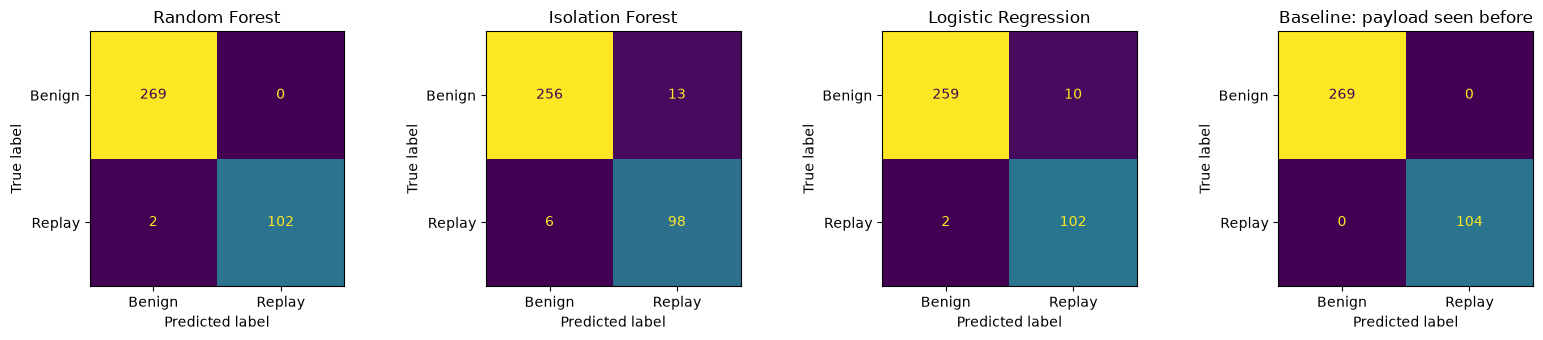

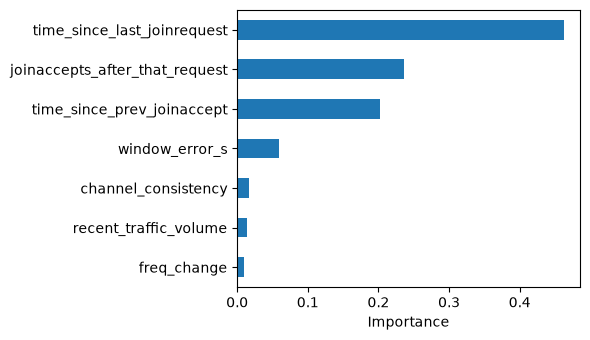

In [11]:
# ---------------------------------------------------------------------
# Figures 4.4 and 4.5
# ---------------------------------------------------------------------
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, (title, pred) in zip(axes, [("Random Forest", rf_pred),
                                    ("Isolation Forest", iso_pred),
                                    ("Logistic Regression", lr_pred),
                                    ("Baseline: payload seen before", baseline_pred_test)]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1],
        display_labels=["Benign", "Replay"], ax=ax, colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.savefig("fig4_4_confusion_matrices.png", dpi=200)
plt.show()

imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(figsize=(6, 3.5))
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("fig4_5_feature_importance.png", dpi=200)
plt.show()


### Repeated timing of the models and the baseline

The training and inference times printed in Step 8 come from a single run, so they vary
from one run to the next. This cell repeats each measurement and reports the median,
which is more stable. These medians are the values reported in Table 4.4 of the
dissertation.

- **Training time:** the median of 20 runs, each fitting a fresh copy of the model on
  the training data. The Isolation Forest is fitted on the benign training rows only.
- **Inference time:** the median of 100 runs predicting on the test set, divided by the
  number of test rows to give microseconds per row. The Isolation Forest is timed
  scoring its five features with `score_samples`.
- **Model size** is not measured here. It comes from the pickled models in Step 8.
- **The payload baseline** is timed in the last two lines of the code below, the same
  way as the models: the median of 100 runs. It is a lookup of precomputed flags, so the
  time excludes the cost of building the flags.

These timings were taken on a development machine (13-inch MacBook Air, Apple M4,
16 GB RAM, macOS 27.0.1, Python 3.14.5, scikit-learn 1.9.0) and show the relative cost
of the models, not the cost on gateway hardware.

In [12]:
import time as _t, statistics
from sklearn.base import clone

def med(fn, n):
    r = []
    for _ in range(n):
        t0 = _t.perf_counter(); fn(); r.append(_t.perf_counter() - t0)
    return statistics.median(r)

rows = []
for name, m, fit_fn, infer_fn, n_rows in [
    ("Random Forest", rf, lambda: clone(rf).fit(X_train, y_train), lambda: rf.predict(X_test), len(X_test)),
    ("Logistic Regression", lr, lambda: clone(lr).fit(X_train, y_train), lambda: lr.predict(X_test), len(X_test)),
    ("Isolation Forest", iso, lambda: clone(iso).fit(benign_train), lambda: iso.score_samples(X_test[IF_FEATURES]), len(X_test)),
]:
    rows.append((name, med(fit_fn, 20) * 1000, med(infer_fn, 100) / n_rows * 1e6))

display(pd.DataFrame(rows, columns=["model", "train_ms", "infer_us_per_row"]).round(2))

base_us = med(lambda: test_df.index.map(payload_seen_before).to_numpy(), 100) / len(test_df) * 1e6
print(f"Baseline: {base_us:.2f} us per row (median of 100 runs)")

,model,train_ms,infer_us_per_row
0,Random Forest,39.12,6.43
1,Logistic Regression,1.94,0.75
2,Isolation Forest,33.83,8.20


Baseline: 0.61 us per row (median of 100 runs)


## Step 9: Show the leakage effect

This step retrains the Random Forest with the "payload seen before" flag added as a
**feature**. In Step 8 the same flag was used as a standalone baseline detector. The
results are then compared.

A replay is defined as a recorded payload appearing again, so the flag is almost a
direct copy of the label. In this dataset that is exactly true: the simulated
Join-Accepts have placeholder payloads, and every replay copies the payload of its seed.
The flag is therefore not a behavioural pattern the model has learned. It raises the
score trivially, and it would not carry over to a real deployment with different devices,
sessions and payloads.

The jump in the scores below is reported only to demonstrate the leakage. It is not a
result, and the flag is left out of the main evaluation in Step 8.

In [13]:
# ---------------------------------------------------------------------
# Step 9 -- Leakage demonstration
# ---------------------------------------------------------------------

train_df["payload_repeated"] = train_df.index.map(payload_seen_before)
test_df["payload_repeated"] = test_df.index.map(payload_seen_before)
LEAK_FEATURES = FEATURES + ["payload_repeated"]

rf_leak = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=SEED)
rf_leak.fit(train_df[LEAK_FEATURES], y_train)
rf_leak_pred = rf_leak.predict(test_df[LEAK_FEATURES])
rf_leak_scores = rf_leak.predict_proba(test_df[LEAK_FEATURES])[:, 1]

_ = evaluate("Random Forest + payload_seen_before (LEAKY -- not a valid result)",
             y_test, rf_leak_pred, rf_leak_scores)

print(
    "\nThe jump above is not a valid result: 'payload_repeated' is almost a direct "
    "encoding of the label by construction (a replay IS a repeated payload), not a "
    "learned behavioural pattern. It is reported only to demonstrate the leakage, "
    "and is excluded from the main evaluation in Step 8."
)



Random Forest + payload_seen_before (LEAKY -- not a valid result)
Confusion matrix [[TN FP] [FN TP]]:
[[269   0]
 [  0 104]]
Precision: 1.000  Recall: 1.000  F1: 1.000  FPR: 0.000  AUC: 1.000

The jump above is not a valid result: 'payload_repeated' is almost a direct encoding of the label by construction (a replay IS a repeated payload), not a learned behavioural pattern. It is reported only to demonstrate the leakage, and is excluded from the main evaluation in Step 8.


## Step 10: Repeat with different seeds

A single run gives one test set, so its scores depend on which Join sessions, replays and
blocks the random seed happened to produce. This step repeats Steps 3 to 8
`N_MULTI_SEED_RUNS` times, each with a different seed, and reports the mean and standard
deviation of each metric across runs. The models, features, purge and split rules are
exactly the same as above; only the random draws change.

This does not make any single test set bigger, but it shows how stable the scores are,
which is the honest way to report results from a partly simulated dataset.


In [14]:
# ---------------------------------------------------------------------
# Step 10 -- Repeat Steps 3-8 over several seeds
# ---------------------------------------------------------------------
import contextlib, io

def run_once(seed: int) -> list[dict]:
    r = np.random.default_rng(seed)
    with contextlib.redirect_stdout(io.StringIO()):   # keep the per-run output quiet
        bg = extend_background(_df, N_CAPTURE_LOOPS)
        benign, _ = inject_simulated_joins(bg, r)
        rep = generate_replays(benign, r)
        st = pd.concat([benign, rep], ignore_index=True).sort_values("capture_time").reset_index(drop=True)
        sf = compute_features(st)
        sb, _, _ = assign_time_blocks(sf)
        ja = sb[(sb["message_type"] == "JoinAccept") & (sb["direction"] == "downlink")].copy()
        ja = ja[ja["dist_from_block_start"] >= LOOKBACK_CAP_S].copy()
        _, _, trm, tem, _, _ = grouped_split(ja, seed)
    tr, te = ja[trm], ja[tem]
    Xtr, ytr, Xte, yte = tr[FEATURES], tr["Label"], te[FEATURES], te["Label"]

    rf_ = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=SEED).fit(Xtr, ytr)
    lr_ = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000,
                                                              random_state=SEED)).fit(Xtr, ytr)
    ben = Xtr[(ytr == 0).to_numpy()][IF_FEATURES]
    if_ = IsolationForest(n_estimators=100, max_features=1.0, random_state=SEED).fit(ben)
    if_thr = np.quantile(-if_.score_samples(ben), 0.95)
    if_s = -if_.score_samples(Xte[IF_FEATURES])

    full = sb[(sb["message_type"] == "JoinAccept") & (sb["direction"] == "downlink")].sort_values("capture_time")
    seen_, flag = set(), {}
    for idx, h in full["payload_hash"].items():
        flag[idx] = int(h in seen_); seen_.add(h)
    base_p = te.index.map(flag).to_numpy()

    out = []
    for name, pred, score in [("Random Forest", rf_.predict(Xte), rf_.predict_proba(Xte)[:, 1]),
                              ("Isolation Forest (benign-only)", (if_s > if_thr).astype(int), if_s),
                              ("Logistic Regression", lr_.predict(Xte), lr_.predict_proba(Xte)[:, 1]),
                              ("Baseline: payload seen before", base_p, base_p)]:
        tn, fp, fn, tp = confusion_matrix(yte, pred, labels=[0, 1]).ravel()
        row = dict(seed=seed, model=name, n_test=len(te), n_test_replay=int(yte.sum()),
                   precision=precision_score(yte, pred, zero_division=0),
                   recall=recall_score(yte, pred, zero_division=0),
                   f1=f1_score(yte, pred, zero_division=0),
                   fpr=fp / max(fp + tn, 1), auc=roc_auc_score(yte, score))
        for sc in ["naive", "timing_aware"]:
            m = (te["scenario"] == sc).to_numpy()
            row[f"recall_{sc}"] = recall_score(yte[m], pred[m], zero_division=0) if m.sum() else np.nan
        out.append(row)
    return out


multi = pd.DataFrame([row for k in range(N_MULTI_SEED_RUNS) for row in run_once(SEED + k)])
sizes = multi.drop_duplicates("seed")[["n_test", "n_test_replay"]]
print(f"{N_MULTI_SEED_RUNS} runs, {N_CAPTURE_LOOPS} capture loop(s): test set per run "
      f"{sizes['n_test'].mean():.0f} rows on average ({sizes['n_test_replay'].mean():.0f} replays)\n")

metrics = ["precision", "recall", "f1", "fpr", "auc", "recall_naive", "recall_timing_aware"]
agg = multi.groupby("model", sort=False)[metrics].agg(["mean", "std"])
summary = pd.DataFrame({m: agg[(m, "mean")].map("{:.3f}".format) + " ± " + agg[(m, "std")].map("{:.3f}".format)
                        for m in metrics})
display(summary.rename_axis("Model (mean ± sd)"))


10 runs, 10 capture loop(s): test set per run 361 rows on average (94 replays)



,precision,recall,f1,fpr,auc,recall_naive,recall_timing_aware
Model (mean ± sd),,,,,,,
Random Forest,0.998 ± 0.004,0.991 ± 0.009,0.994 ± 0.004,0.001 ± 0.002,1.000 ± 0.000,0.991 ± 0.016,0.991 ± 0.012
Isolation Forest (benign-only),0.883 ± 0.051,0.942 ± 0.050,0.909 ± 0.025,0.045 ± 0.021,0.988 ± 0.005,1.000 ± 0.000,0.878 ± 0.103
Logistic Regression,0.932 ± 0.032,0.981 ± 0.012,0.956 ± 0.016,0.025 ± 0.012,0.998 ± 0.001,0.991 ± 0.014,0.970 ± 0.023
Baseline: payload seen before,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000


## Step 11: Extra checks reported in the dissertation

This cell computes the supporting figures quoted in the dissertation that the steps above
do not print directly:

- the size and range of the latency pool used for simulated Join-Accepts (Section 3.3);
- how many replay sessions injected one, two or three copies (Section 3.4.1);
- median feature values by class, and how many benign test rows follow another
  Join-Accept after the same request (Section 4.2);
- the Random Forest's missed replays (Section 4.4);
- each feature's AUC on its own, and a simple rule that flags any second Join-Accept
  after the same request (Section 5.1).

It only reads results from Steps 2b to 8 and does not retrain anything, so it can be run
on its own without changing the timings in Table 4.4.


In [15]:
# ---------------------------------------------------------------------
# Step 11 -- Extra checks reported in Chapters 3 to 5
# ---------------------------------------------------------------------
from sklearn.metrics import roc_auc_score, confusion_matrix

# Latency pool used for simulated Join-Accepts (Section 3.3)
bg = extend_background(_df, N_CAPTURE_LOOPS).sort_values("capture_time")
up = bg.loc[bg["direction"] == "uplink", "capture_time"].to_numpy()
dn = bg.loc[bg["direction"] == "downlink", "capture_time"].to_numpy()
pos = np.searchsorted(up, dn) - 1
lat = dn[pos >= 0] - up[pos[pos >= 0]]
lat = lat[(lat > 0) & (lat < 2.0)]
print(f"Latency pool: {len(lat)} delays, {lat.min():.2f} to {lat.max():.2f} s")

# Copies per replay session (Section 3.4.1)
print("Sessions by number of copies:", replays.groupby("session_id").size().value_counts().sort_index().to_dict())

# Median feature values by class (Section 4.2)
display(ja_rows.groupby("Label")[FEATURES].median().round(3))

# Benign test rows that follow another Join-Accept after the same request (Section 4.2)
print("Benign test rows with joinaccepts_after_that_request >= 1:",
      int(((y_test == 0) & (X_test["joinaccepts_after_that_request"] >= 1)).sum()))

# Each feature on its own (Section 5.1): AUC in the better direction
single = {f: max(roc_auc_score(y_test, X_test[f]), 1 - roc_auc_score(y_test, X_test[f])) for f in FEATURES}
display(pd.Series(single).sort_values(ascending=False).round(3).rename("single-feature AUC"))

# Simple state rule (Section 5.1): flag any second Join-Accept after the same request
rule = (X_test["joinaccepts_after_that_request"] >= 1).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, rule, labels=[0, 1]).ravel()
print(f"Rule: caught {tp} of {tp + fn} replays, {fp} false positives")

# Replays the Random Forest missed (Section 4.4)
display(test_df[(y_test == 1).to_numpy() & (rf_pred == 0)][["scenario"] + FEATURES])


Latency pool: 1300 delays, 0.23 to 0.45 s
Sessions by number of copies: {1: 47, 2: 55, 3: 48}


,time_since_prev_joinaccept,time_since_last_joinrequest,joinaccepts_after_that_request,window_error_s,channel_consistency,freq_change,recent_traffic_volume
Label,,,,,,,
0,10.453,0.327,0.0,0.000,1.0,0.0,5.0
1,0.743,1.940,2.0,0.104,1.0,0.0,6.0


Benign test rows with joinaccepts_after_that_request >= 1: 27


time_since_last_joinrequest       0.990
joinaccepts_after_that_request    0.961
time_since_prev_joinaccept        0.848
window_error_s                    0.786
channel_consistency               0.739
recent_traffic_volume             0.633
freq_change                       0.580
Name: single-feature AUC, dtype: float64

Rule: caught 103 of 104 replays, 27 false positives


,scenario,time_since_prev_joinaccept,time_since_last_joinrequest,joinaccepts_after_that_request,window_error_s,channel_consistency,freq_change,recent_traffic_volume
2328,naive,5.722889,0.015991,0,60.0,0,1,8
3141,timing_aware,0.069397,0.401119,1,0.0,1,0,4


## Interpretation and limitations

- **This is a controlled, partly simulated proof of concept.** Real Join-Accept traffic is
  used wherever the capture has enough of it, and Step 3 checks this explicitly. In this
  run the capture held only 1 real Join-Accept. The real background traffic was looped
  10 times (Step 2b), so 10 of the 836 benign Join-Accepts are copies of that real one and
  the other 826 are simulated. The replay attacks themselves are always simulated
  (Step 4).
- **Looping repeats the background.** The looped capture is real traffic, but the same
  15-minute pattern of data frames repeats every loop, so it adds no new variety in the
  background. Two features read the background (`freq_change` and
  `recent_traffic_volume`), so a test Join-Accept can sit in a background context that
  also appears in training. The Join sessions and replays are drawn fresh in every loop,
  and the five protocol features do not read the background at all. Setting
  `N_CAPTURE_LOOPS = 1` reproduces the original single-capture run.
- **Expected and observed attacker difficulty.** The naive attacker was designed as the
  easy case (stale timing and a wrong radio profile), and the timing-aware attacker as
  the hard case (correct timing and radio profile). The expectation was therefore higher
  recall for the naive attacker. Across the 10 seeds in Step 10 the naive copies are
  caught almost every time by all three models (recall 0.99 to 1.00). Timing-aware recall
  is slightly lower for Logistic Regression (0.97) and clearly lower for the Isolation
  Forest (0.88, with the widest spread, ± 0.10). The Random Forest catches both equally
  (0.99). In the single-capture run, with only a handful of test replays of each kind, this
  pattern was hidden by chance.
- **Leakage.** Apart from the payload baseline, the labels are used only to balance the replay
  rate between the training and test blocks (Step 6); no feature or model setting is
  chosen using them. An earlier version of the simulation leaked through timing: 87% of benign
  Join-Accepts were exactly 5.000 or 6.000 s after their request, against 0% of replays,
  so a model could tell the classes apart by how they were generated. Benign Join-Accepts now use the real capture's network-server latency.
- **One feature is almost decisive.** With realistic latency, benign Join-Accepts reach
  the gateway 0.23 to 0.45 s after their request, while timing-aware replays arrive 0.05
  to 0.8 s after the legitimate Join-Accept. `time_since_last_joinrequest` alone
  therefore reaches an AUC of 0.99. This is not leakage: it follows from the attacker
  model. It does mean the timing-aware attacker is easier to catch than a real
  slot-aware attacker who matched the network server's latency, so the timing-aware
  results are an upper bound.
- **Test set size.** The single capture gave a test set with only 6 replays. With 10
  loops it is 373 rows (104 replays) in the main run and about 361 on average (94
  replays) across the 10 seeds in Step 10. Step 10's standard deviations show how much the scores
  move between seeds; report those alongside the single-run values. A longer real
  capture would still be better than looping, because it would add genuinely new
  background traffic.
- **No real-world claim.** Real gateway and device captures from several deployments
  would be needed before making any claim about detection performance in deployment.